# Online Retail Sales and Customer Analysis

**Dataset:** UCI Online Retail (United Kingdom-based retailer, 1 December 2010–9 December 2011)  
**Tools:** Python, Pandas, Matplotlib  
**Scope:** Six business questions about sales, products, customers, geography, repeat purchases, and transaction timing.

The analysis distinguishes **gross merchandise sales**, **recorded cancellations**, and **separate accounting/inventory adjustments**. Results describe the historical dataset, not present-day performance.

**How to reproduce:** Place `Online_Retail.xlsx` alongside this notebook, install the required libraries (`pandas`, `matplotlib`, `openpyxl`), then use **Run All** in Jupyter/Colab. The uploaded notebook was reorganized without executing it again because the source workbook was not attached.

## 1. Setup and Dataset Overview

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

In [4]:
df = pd.read_excel('Online_Retail.xlsx')

### Inspect the transaction-level data
Each row represents an invoice **line item**, not necessarily a unique order. We inspect structure, completeness, and the number of records before analyzing sales.

In [5]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [6]:
df.shape  # (number of rows, number of columns); df.size counts individual cells

(541909, 8)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 2. Data Quality, Transaction Classification, and Reconciliation

### 2.1. Create and inspect revenue values

In [8]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [9]:
df.tail(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
541894,581587,22631,CIRCUS PARADE LUNCH BOX,12,2011-12-09 12:50:00,1.95,12680.0,France,23.40
541895,581587,22556,PLASTERS IN TIN CIRCUS PARADE,12,2011-12-09 12:50:00,1.65,12680.0,France,19.80
541896,581587,22555,PLASTERS IN TIN STRONGMAN,12,2011-12-09 12:50:00,1.65,12680.0,France,19.80
541897,581587,22728,ALARM CLOCK BAKELIKE PINK,4,2011-12-09 12:50:00,3.75,12680.0,France,15.00
541898,581587,22727,ALARM CLOCK BAKELIKE RED,4,2011-12-09 12:50:00,3.75,12680.0,France,15.00
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,2011-12-09 12:50:00,3.75,12680.0,France,15.00
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,2011-12-09 12:50:00,3.75,12680.0,France,15.00
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,2011-12-09 12:50:00,1.95,12680.0,France,15.60
541902,581587,22629,SPACEBOY LUNCH BOX,12,2011-12-09 12:50:00,1.95,12680.0,France,23.40
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


**Zero-priced and negative-priced records.** Zero-price movements may represent non-sales stock changes; negative unit prices require separate review.

In [10]:
(df['UnitPrice'] <= 0).sum()

np.int64(2517)

In [11]:
df[df['UnitPrice'] == 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,0.0
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,0.0
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
...,...,...,...,...,...,...,...,...,...
536981,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom,0.0
538504,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom,0.0
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom,0.0
538554,581408,85175,NaN,20,2011-12-08 14:06:00,0.0,NaN,United Kingdom,0.0


In [12]:
df[df['StockCode'] == '46000M']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
918,536500,46000M,POLYESTER FILLER PAD 45x45cm,10,2010-12-01 12:35:00,1.55,17377.0,United Kingdom,15.50
11712,537265,46000M,POLYESTER FILLER PAD 45x45cm,2,2010-12-06 11:26:00,1.55,15919.0,United Kingdom,3.10
14042,537446,46000M,POLYESTER FILLER PAD 45x45cm,2,2010-12-07 09:13:00,1.55,18055.0,United Kingdom,3.10
16359,537653,46000M,POLYESTER FILLER PAD 45x45cm,6,2010-12-07 15:54:00,1.55,17897.0,United Kingdom,9.30
22297,538162,46000M,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom,-0.00
...,...,...,...,...,...,...,...,...,...
519974,580208,46000M,POLYESTER FILLER PAD 45x45cm,4,2011-12-02 12:07:00,1.55,13468.0,United Kingdom,6.20
520784,580300,46000M,POLYESTER FILLER PAD 45x45cm,9,2011-12-02 14:02:00,1.55,14085.0,United Kingdom,13.95
527009,580689,46000M,POLYESTER FILLER PAD 45x45cm,10,2011-12-05 15:43:00,1.55,12994.0,United Kingdom,15.50
534562,581150,46000M,POLYESTER FILLER PAD 45x45cm,1,2011-12-07 14:12:00,1.55,17266.0,United Kingdom,1.55


In [13]:
df[df['StockCode'] == '46000S']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
2039,536557,46000S,POLYESTER FILLER PAD 40x40cm,1,2010-12-01 14:41:00,1.45,17841.0,United Kingdom,1.45
4875,536813,46000S,POLYESTER FILLER PAD 40x40cm,2,2010-12-02 16:59:00,1.45,15646.0,United Kingdom,2.90
14792,537619,46000S,POLYESTER FILLER PAD 40x40cm,12,2010-12-07 13:53:00,1.45,13786.0,United Kingdom,17.40
22296,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom,-0.00
32752,539118,46000S,POLYESTER FILLER PAD 40x40cm,25,2010-12-16 11:27:00,1.45,15563.0,United Kingdom,36.25
...,...,...,...,...,...,...,...,...,...
520653,580295,46000S,POLYESTER FILLER PAD 40x40cm,2,2011-12-02 13:49:00,1.45,17841.0,United Kingdom,2.90
522733,580438,46000S,POLYESTER FILLER PAD 40x40cm,10,2011-12-04 12:17:00,1.45,12827.0,United Kingdom,14.50
531659,580958,46000S,POLYESTER FILLER PAD 40x40cm,1,2011-12-06 14:30:00,1.45,17266.0,United Kingdom,1.45
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.00,NaN,United Kingdom,0.00


In [14]:
df[df['UnitPrice'] < 0].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,-11062.06
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,-11062.06


### 2.2. Cancellations and non-sales stock movements

In [15]:
(df['Quantity'] <= 0).sum()

np.int64(10624)

checking the records with quantity less than '0', noticed that most of them seem to have been canceled orders.

In [16]:
df[df['Quantity'] < 0].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom,-41.40
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-39.60
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom,-25.50


Confirming if all the records with negative quantities actually are cancelled orders. Only 9288 rows are cancelled orders meaning the other 1,336 rcords need to be further investigated

In [17]:
df[(df['Quantity'] < 0) & df['InvoiceNo'].str.startswith('C', na=False)].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom,-41.40
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-39.60
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom,-25.50


checking if cancelled orders have a negative or zero price

In [18]:
df[(df['Quantity'] < 0) & df['InvoiceNo'].str.startswith('C', na=False) & (df['UnitPrice'] <= 0)].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice


In [19]:
df['InvoiceNo'].str.startswith('C', na=False).sum()

np.int64(9288)

Checking the negative quantity records that aren't part of cancelled orders

In [20]:
df[~df['InvoiceNo'].str.startswith('C', na=False) & (df['Quantity'] < 0)].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom,-0.0
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom,-0.0
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom,-0.0
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom,-0.0


identified 1,336 records with negative quantities, zero unit prices, and invoice numbers without cancellation markers. Descriptions suggest inventory adjustments, including missing, damaged, and lost stock. These records will be excluded from sales-revenue analysis while being retained in the raw dataset.

In [21]:
df_non_c_negative = df[
    (~df['InvoiceNo'].str.startswith('C', na=False))
    & (df['Quantity'] < 0)
]

df_non_c_negative['UnitPrice'].value_counts()

,count
UnitPrice,
0.0,1336


### 2.3. Define merchandise-sales transactions

In [22]:
Positive_sales_df = df[
    (~df['InvoiceNo'].str.startswith('C', na=False))
    & (df['Quantity'] > 0)
    & (df['UnitPrice'] > 0)
]

In [23]:
Cancelled_sales_df = df[
    (df['InvoiceNo'].str.startswith('C', na=False))
]

In [24]:
gross_sales = Positive_sales_df['TotalPrice'].sum()
print(f'Gross sales: GBP {gross_sales:,.2f}')

Gross sales: GBP 10,666,684.54


In [25]:
cancelled_value_total = -Cancelled_sales_df['TotalPrice'].sum()
cancelled_value_total

np.float64(896812.49)

In [26]:
net_sales = gross_sales - cancelled_value_total
print(f'Net Sales: GBP {net_sales:,.2f}')

Net Sales: GBP 9,769,872.05


In [27]:
Cancellation_rate = (cancelled_value_total / gross_sales) * 100
print(f'Cancellation rate: {Cancellation_rate:.2f}%')

Cancellation rate: 8.41%


In [28]:
sales_transactions_df = pd.concat(
    [Positive_sales_df, Cancelled_sales_df]
).sort_index()

**Revenue definitions:** Gross merchandise sales consist of non-cancellation entries with positive quantity and positive unit price. Cancellation invoices are recorded separately and subtracted to estimate net merchandise sales. Other transactions remain in the original `df` for auditing.

The reported £22,124.12 difference between merchandise sales and a direct sum of all `TotalPrice` values is attributable to two **bad-debt adjustments**, each −£11,062.06. These are accounting adjustments, not sales or product returns.

### 2.4. Reconcile every source row and the revenue total

In [78]:

excluded_rows = df[
    ~df.index.isin(Positive_sales_df.index)
    & ~df.index.isin(Cancelled_sales_df.index)
]

sales_overlap = Positive_sales_df.index.intersection(Cancelled_sales_df.index)
accounted_rows = len(Positive_sales_df) + len(Cancelled_sales_df) + len(excluded_rows)
reconciled_revenue = (
    Positive_sales_df['TotalPrice'].sum()
    + Cancelled_sales_df['TotalPrice'].sum()
    + excluded_rows['TotalPrice'].sum()
)
print(f'Overlapping original rows: {len(sales_overlap):,}')
print(f'Rows accounted for: {accounted_rows:,} / {len(df):,}')
print(f'Excluded rows: {len(excluded_rows):,}')
print(f'Excluded monetary value: £{excluded_rows["TotalPrice"].sum():,.2f}')
print(f'Revenue difference after reconciliation: £{df["TotalPrice"].sum() - reconciled_revenue:,.2f}')

assert len(sales_overlap) == 0
assert accounted_rows == len(df)
assert abs(df['TotalPrice'].sum() - reconciled_revenue) < 0.01

Overlapping original rows: 0
Rows accounted for: 541,909 / 541,909
Excluded rows: 2,517
Excluded monetary value: £-22,124.12
Revenue difference after reconciliation: £0.00


### 2.5. Duplicate-record assessment

In [30]:
df.duplicated().sum()

np.int64(5268)

In [31]:
duplicate_rows = df[df.duplicated(keep=False)]
duplicate_rows.sort_values(['InvoiceNo', 'StockCode']).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,3.30
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,1.65


In [32]:
duplicate_impact = df.loc[df.duplicated(), 'TotalPrice'].sum()

print(f'Duplicate rows: {df.duplicated().sum():,}')
print(f'Potential revenue impact: £{duplicate_impact:,.2f}')

Duplicate rows: 5,268
Potential revenue impact: £21,740.98


In [33]:
duplicate_impact_percentage = (
    duplicate_impact / sales_transactions_df['TotalPrice'].sum()
) * 100

print(f'Potential revenue impact: {duplicate_impact_percentage:.2f}%')

Potential revenue impact: 0.22%


In [34]:
# Same-population sensitivity check for merchandise revenue.
merchandise_duplicate_impact = sales_transactions_df.loc[
    sales_transactions_df.duplicated(), 'TotalPrice'
].sum()
merchandise_duplicate_pct = (
    merchandise_duplicate_impact / sales_transactions_df['TotalPrice'].sum() * 100
)
print(f'Merchandise-only duplicate impact: £{merchandise_duplicate_impact:,.2f}')
print(f'Percent of net merchandise sales: {merchandise_duplicate_pct:.2f}%')

Merchandise-only duplicate impact: £21,740.98
Percent of net merchandise sales: 0.22%


**Decision — retain exact duplicates in the primary analysis.** The original data contains 5,268 exact duplicated rows. Their removal would change the original recorded monetary total by approximately **£21,740.98**, or about **0.22%** of reported net merchandise sales when used as a sensitivity benchmark. The dataset lacks a unique invoice-line identifier, so identical rows cannot be confidently classified as accidental duplicates rather than legitimate repeated line items. The merchandise-only sensitivity check above makes the comparison using one consistent transaction population. **This uncertainty is a documented limitation**, not proof that every repeated row is valid.

## 3. Business Question 1 — How Does Monthly Sales Performance Change?

In [35]:
group_sales_gross_df = Positive_sales_df.groupby(pd.Grouper(key='InvoiceDate', freq='MS'))
monthly_gross = group_sales_gross_df['TotalPrice'].sum()

In [36]:
group_cancelled_df = Cancelled_sales_df.groupby(pd.Grouper(key='InvoiceDate', freq='MS'))
monthly_cancelled = -group_cancelled_df['TotalPrice'].sum()

In [37]:
monthly_net_direct = df.groupby(
    pd.Grouper(key='InvoiceDate', freq='MS')
)['TotalPrice'].sum()

monthly_net_calculated = monthly_gross - monthly_cancelled

**Reconciliation note:** The `monthly_net_direct` series includes bad-debt adjustments, whereas `monthly_net_calculated` estimates merchandise revenue after recorded cancellation invoices. These are deliberately different measures.

In [38]:
Monthly_sales_df = pd.DataFrame({
    'Gross Sales': monthly_gross,
    'Cancelled Sales': monthly_cancelled,
    'Net Sales': monthly_net_calculated,
})
Monthly_sales_df.index = Monthly_sales_df.index.strftime('%b %Y')
Monthly_sales_df.head()

,Gross Sales,Cancelled Sales,Net Sales
InvoiceDate,,,
Dec 2010,823746.140,74789.12,748957.020
Jan 2011,691364.560,131364.30,560000.260
Feb 2011,523631.890,25569.24,498062.650
Mar 2011,717639.360,34372.28,683267.080
Apr 2011,537808.621,44601.50,493207.121


In [39]:
Monthly_sales_df.sum()

,0
Gross Sales,1.066668e+07
Cancelled Sales,8.968125e+05
Net Sales,9.769872e+06


In [40]:
Monthly_sales_df[Monthly_sales_df.index.str.contains('Dec 2011')]

,Gross Sales,Cancelled Sales,Net Sales
InvoiceDate,,,
Dec 2011,638792.68,205124.67,433668.01


From December 2010 through August 2011, monthly sales fluctuated within a relatively consistent range, without a clear sustained upward or downward trend. However, beginning in September 2011, sales increased significantly, reaching their highest level in November 2011. February 2011 recorded the lowest net sales among the complete months, at approximately £498,063.

Although December 2011 appears to show a substantial decline, the available data covers only part of the month. Therefore, additional data would be required before drawing conclusions about December's overall performance.

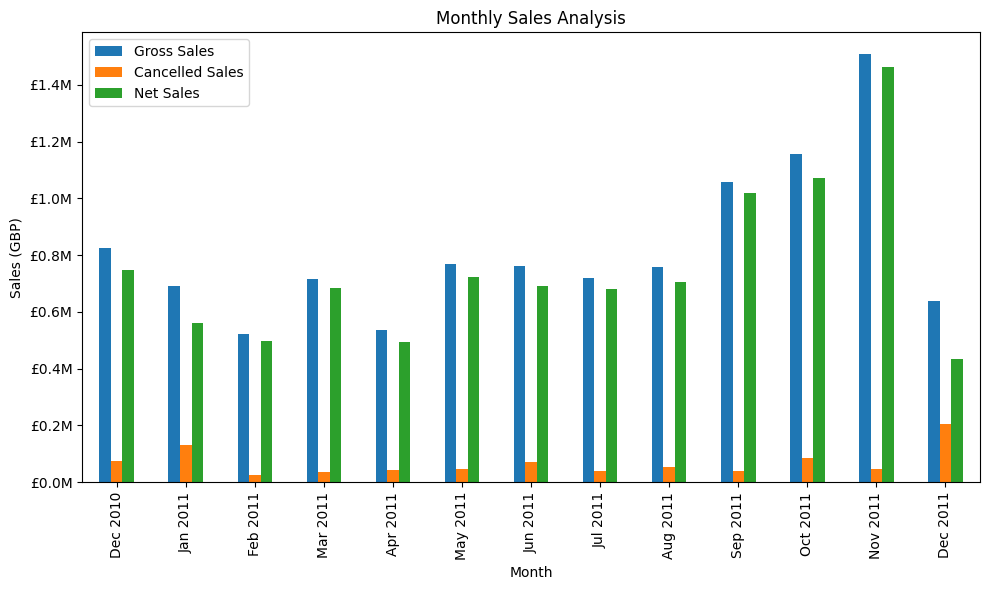

In [41]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x/1_000_000:.1f}M')
)
Monthly_sales_df.plot(
    kind='bar',
    ax=ax,
    title='Monthly Sales Analysis',
    xlabel='Month',
    ylabel='Sales (GBP)'
)
plt.tight_layout()
plt.savefig('Monthly_sales_analysis.png')

## 4. Business Question 2 — Which Products Drive Volume and Revenue?

**Method:** Product performance is ranked using the **net** quantity and revenue after recorded cancellations. Non-product codes and gift-card placeholders are excluded from the final product ranking. Earlier gross-only exploratory rankings have been omitted to avoid confusing them with the final results.

In [42]:
exclude_codes = ['DOT', 'POST', 'M']

Product_sales_df = Positive_sales_df[
    ~Positive_sales_df['StockCode'].isin(exclude_codes)
].copy()
Product_sales_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


### Inspect an extreme transaction and cancellation pair

In [43]:
df[df['StockCode'].astype(str) == '23843']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,-168469.6


### Build final net product rankings

In [44]:
Net_sales_df = pd.concat(
    [Product_sales_df, Cancelled_sales_df],
    ignore_index=True
)

Net_sales_df['StockCode'] = Net_sales_df['StockCode'].astype(str).str.upper()

Net_sales_df = Net_sales_df[
    ~Net_sales_df['StockCode'].astype(str).str.upper().isin(exclude_codes)
    & ~Net_sales_df['StockCode'].astype(str).str.lower().str.startswith('gift_')
].copy()

Net_sales_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [45]:
group_net_sales_df = Net_sales_df.groupby(['Description', 'StockCode'])

In [46]:
total_product_net_sales_df = group_net_sales_df['Quantity'].sum()

In [47]:
total_product_net_revenue_df = group_net_sales_df['TotalPrice'].sum()

In [48]:
net_revenue_per_product = pd.concat(
    [total_product_net_sales_df, total_product_net_revenue_df],
    axis=1
)

net_revenue_per_product.head()

,,Quantity,TotalPrice
Description,StockCode,,
4 PURPLE FLOCK DINNER CANDLES,72800B,144,290.80
50'S CHRISTMAS GIFT BAG LARGE,23437,1913,2341.13
DOLLY GIRL BEAKER,23345,2448,2882.50
I LOVE LONDON MINI BACKPACK,23391,389,1628.17
I LOVE LONDON MINI RUCKSACK,23391,1,4.15


In [49]:
top_10_by_quantity = net_revenue_per_product.sort_values(
    by='Quantity',
    ascending=False
).head(10)

top_10_by_quantity

,,Quantity,TotalPrice
Description,StockCode,,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,84077,53847,13587.93
JUMBO BAG RED RETROSPOT,85099B,47359,92356.03
ASSORTED COLOUR BIRD ORNAMENT,84879,36381,58959.73
POPCORN HOLDER,22197,36334,33969.46
PACK OF 72 RETROSPOT CAKE CASES,21212,36039,21059.72
WHITE HANGING HEART T-LIGHT HOLDER,85123A,35313,99668.47
RABBIT NIGHT LIGHT,23084,30680,66756.59
MINI PAINT SET VINTAGE,22492,26437,16810.42
PACK OF 12 LONDON TISSUES,22616,26111,7972.76


In [50]:
top_10_by_revenue = net_revenue_per_product.sort_values(
    by='TotalPrice',
    ascending=False
).head(10)

top_10_by_revenue

,,Quantity,TotalPrice
Description,StockCode,,
REGENCY CAKESTAND 3 TIER,22423,13022,164762.19
WHITE HANGING HEART T-LIGHT HOLDER,85123A,35313,99668.47
PARTY BUNTING,47566,18018,98302.98
JUMBO BAG RED RETROSPOT,85099B,47359,92356.03
RABBIT NIGHT LIGHT,23084,30680,66756.59
PAPER CHAIN KIT 50'S CHRISTMAS,22086,18902,63791.94
ASSORTED COLOUR BIRD ORNAMENT,84879,36381,58959.73
CHILLI LIGHTS,79321,10226,53768.06
SPOTTY BUNTING,23298,8217,42065.32


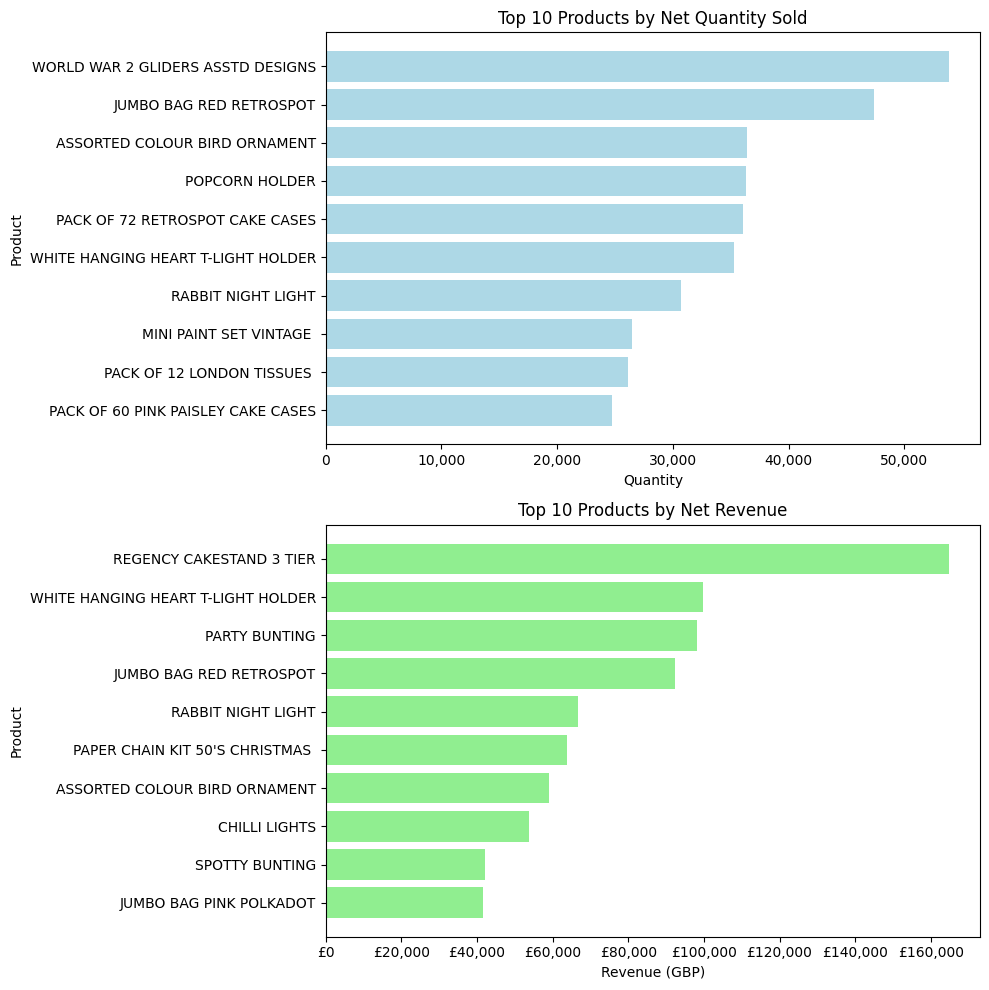

In [51]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

ax1.barh(
    top_10_by_quantity.index.get_level_values('Description'),
    top_10_by_quantity['Quantity'],
    color='lightblue',
)

ax1.invert_yaxis()
ax1.set_xlabel('Quantity')
ax1.set_ylabel('Product')
ax1.set_title('Top 10 Products by Net Quantity Sold')
ax1.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x:,.0f}')
)

ax2.barh(
    top_10_by_revenue.index.get_level_values('Description'),
    top_10_by_revenue['TotalPrice'],
    color='lightgreen',
)

ax2.invert_yaxis()
ax2.set_xlabel('Revenue (GBP)')
ax2.set_ylabel('Product')
ax2.set_title('Top 10 Products by Net Revenue')
ax2.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x:,.0f}')
)

plt.tight_layout()
plt.savefig('Top_10_products.png')


The analysis reveals a clear difference between products generating high sales volumes and those contributing the most revenue. World War 2 Gliders recorded the highest net quantity sold at 53,847 units, generating £13,587.93, while Regency Cakestand 3 Tier generated the highest net revenue of £164,762.19 from just 13,022 units.

These findings suggest that businesses should consider both sales volume and revenue when evaluating product performance. High-volume products may support consistent sales activity, while high-revenue products make a greater monetary contribution. A balanced inventory strategy could therefore help maintain product availability across both categories.

## 5. Business Question 3 — Who Are the Highest-Value Customers?

**Method:** Customer-level calculations use records with known `CustomerID` and positive unit price. Purchase frequency counts unique non-cancelled invoice numbers. The AOV here is **gross purchase AOV**; cancelled purchases do not reduce its numerator.

In [52]:
Customers_df = df[(
    df['CustomerID'].notnull())
    & (df['UnitPrice'] > 0) & (~df['StockCode'].isin(exclude_codes))
].copy()

In [53]:
grouped_customers_df = Customers_df.groupby('CustomerID')
total_customers_by_quantity = grouped_customers_df['Quantity'].sum()
total_customers_by_revenue = grouped_customers_df['TotalPrice'].sum()

In [54]:
sorted_customers_by_revenue = total_customers_by_revenue.sort_values(
    ascending=False
)
top_10_customer_revenue = sorted_customers_by_revenue.head(10).sum()
total_customer_revenue = total_customers_by_revenue.sum()
top_10_revenue_percentage = (top_10_customer_revenue / total_customer_revenue) * 100

top_10_revenue_percentage

np.float64(16.60326013895963)

In [55]:
customers_without_c_df = Customers_df[~Customers_df['InvoiceNo'].str.contains('C', na=False)]
grouped_customers = customers_without_c_df.groupby('CustomerID')['InvoiceNo'].nunique()
customers_sorted = grouped_customers.sort_values(ascending=False)

In [56]:
grouped_customers_revenue = customers_without_c_df.groupby('CustomerID')['TotalPrice'].sum()
customers_revenue = grouped_customers_revenue.sort_values(ascending=False)

In [57]:
aov = customers_revenue / customers_sorted
aov.sort_values(ascending=False).head(10)

,0
CustomerID,
16446.0,84236.250000
12346.0,77183.600000
15749.0,14844.766667
15098.0,13305.500000
12590.0,9341.260000
12415.0,6228.226500
12357.0,6207.670000
12688.0,4873.810000
12752.0,4366.780000


In [58]:
overall_aov = grouped_customers_revenue.sum() / grouped_customers.sum()
overall_aov

np.float64(476.1032609687228)

### Purchase frequency vs. average order value

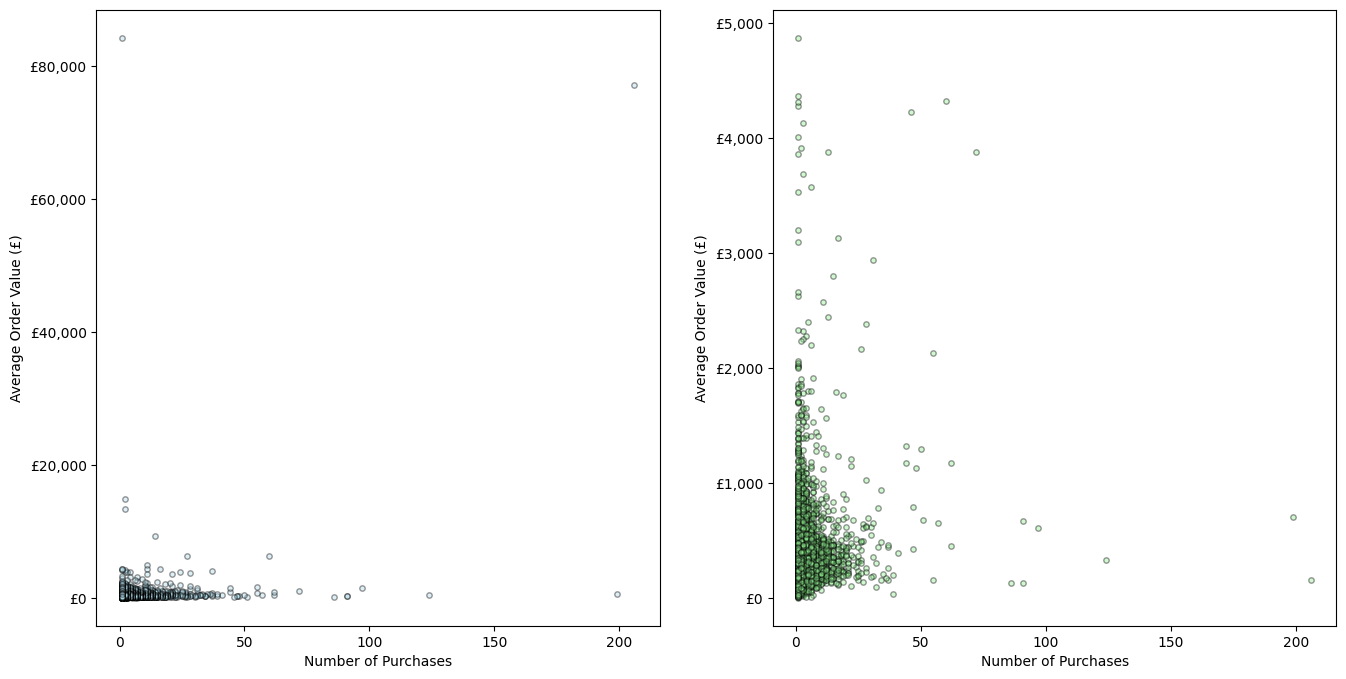

In [59]:
filtered_aov = aov[aov < 5000]

fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(16, 8))

ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x:,.0f}')
)
ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x:,.0f}')
)

ax1.scatter(
    x=customers_sorted,
    y=aov,
    color='lightblue',
    edgecolors='black',
    alpha=0.4,
    s=15,
)

ax1.set_xlabel('Number of Purchases')
ax1.set_ylabel('Average Order Value (£)')

ax2.scatter(
    x=customers_sorted.loc[filtered_aov.index],
    y=filtered_aov,
    color='lightgreen',
    edgecolors='black',
    alpha=0.4,
    s=15,
)

ax2.set_xlabel('Number of Purchases')
ax2.set_ylabel('Average Order Value (£)')

fig.savefig('pf_vs_aov.png')


In [60]:
correlation = customers_sorted.corr(filtered_aov)
print(f'Correlation between number of purchases and AOV: {correlation:.2f}')

Correlation between number of purchases and AOV: 0.12


Purchase frequency and average order value showed a very weak positive correlation (r = 0.12) among customers with AOV below £5,000. This suggests that frequent customers do not necessarily place higher-value orders. The business should consider both purchase frequency and spending when identifying valuable customers.

## 6. Business Question 4 — Which Countries Generate the Most Revenue?

**Method:** These figures use `sales_transactions_df`, consistently excluding accounting adjustments while including recorded merchandise cancellations.

In [61]:
sales_by_country = (
    sales_transactions_df
    .groupby('Country')['TotalPrice']
    .sum()
)
sales_by_country.sort_values(ascending=False).head(10)

,TotalPrice
Country,
United Kingdom,8209930.484
Netherlands,284661.540
EIRE,263276.820
Germany,221698.210
France,197403.900
Australia,137077.270
Switzerland,56385.350
Spain,54774.580
Belgium,40910.960


In [62]:
total_revenue = sales_by_country.sum()
total_revenue

np.float64(9769872.054)

In [63]:
revenue_contribution = (
    sales_by_country / sales_by_country.sum() * 100
)
revenue_contribution.sort_values(ascending=False).head(10)

,TotalPrice
Country,
United Kingdom,84.033142
Netherlands,2.913667
EIRE,2.694783
Germany,2.269203
France,2.020537
Australia,1.403061
Switzerland,0.577135
Spain,0.560648
Belgium,0.418746


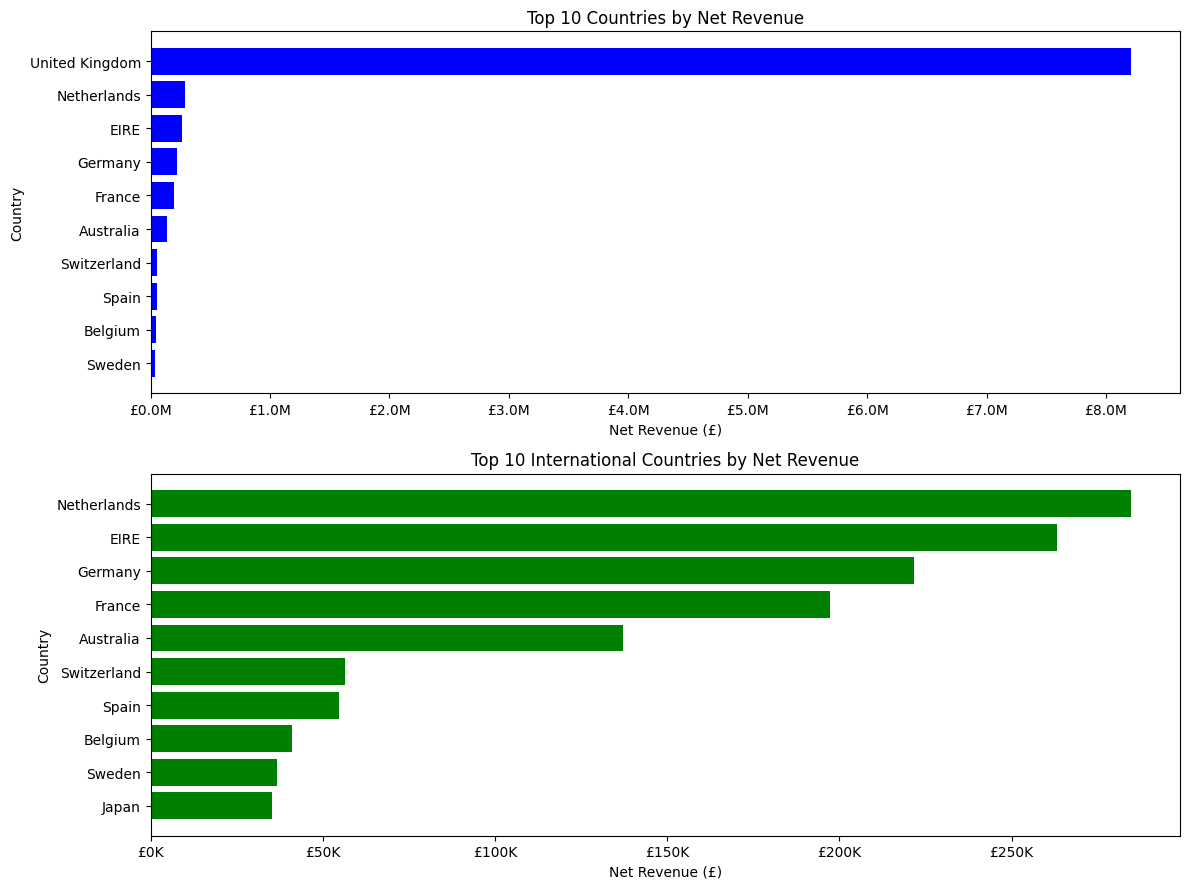

In [64]:
top_10_countries = sales_by_country.sort_values(ascending=False).head(10)
international_sales = sales_by_country.drop('United Kingdom')
top_10_international_sales = international_sales.sort_values(ascending=False).head(10)

fig, [ax1, ax2] = plt.subplots(2,1, figsize=(12, 9))

ax1.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x/1_000_000:.1f}M')
)
ax2.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x/1_000:.0f}K')
)

ax1.barh(
    y=top_10_countries.index,
    width=top_10_countries.values,
    color='blue',
)

ax2.barh(
    y=top_10_international_sales.index,
    width=top_10_international_sales.values,
    color='green',
)

ax1.set_title('Top 10 Countries by Net Revenue')
ax1.set_xlabel('Net Revenue (£)')
ax1.set_ylabel('Country')

ax2.set_title('Top 10 International Countries by Net Revenue')
ax2.set_xlabel('Net Revenue (£)')
ax2.set_ylabel('Country')

fig.tight_layout()

ax1.invert_yaxis()
ax2.invert_yaxis()
fig.savefig('the_top_10_countries_by_net_revenue.png')

## 7. Business Question 5 — How Common Are Repeat Purchases?

**Method:** A repeat purchaser is a customer with more than one unique non-cancelled invoice during the observation period. This is not a cohort-based retention rate.

In [65]:
(grouped_customers == 1).sum()

np.int64(1505)

In [66]:
(grouped_customers > 1).sum()

np.int64(2830)

In [67]:
((grouped_customers > 1).sum() / (grouped_customers).count()) * 100

np.float64(65.28258362168397)

In [68]:
grouped_customers.mean()

np.float64(4.248212226066897)

In [69]:
grouped_customers.median()

2.0

In [70]:
grouped_customers.max()

206

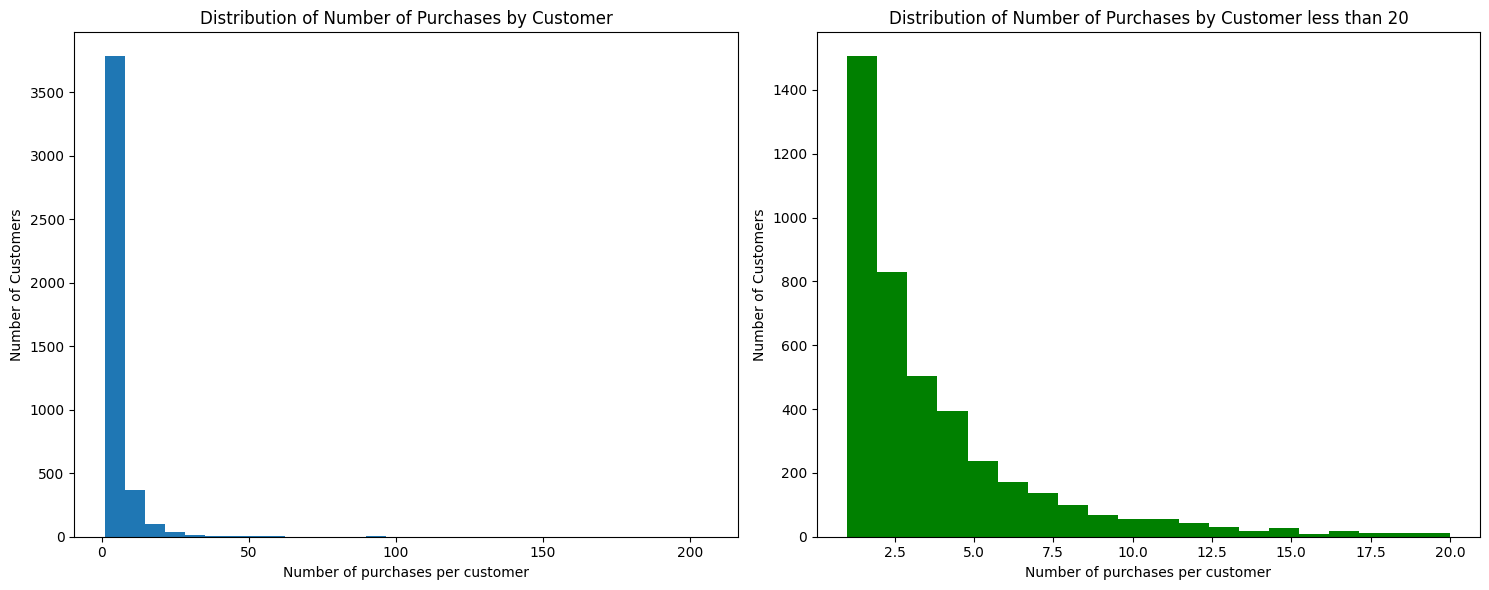

In [71]:
filtered_purchases = grouped_customers[grouped_customers <= 20]
fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(15, 6))

ax1.hist(grouped_customers, bins=30)
ax1.set_xlabel('Number of purchases per customer')
ax1.set_ylabel('Number of Customers')
ax1.set_title('Distribution of Number of Purchases by Customer')

ax2.hist(filtered_purchases, bins=20, color='green')
ax2.set_xlabel('Number of purchases per customer')
ax2.set_ylabel('Number of Customers')
ax2.set_title('Distribution of Number of Purchases by Customer less than 20')

fig.tight_layout()

fig.savefig('distribution_of_number_of_purchases_by_customer.png')

The business has a substantial repeat-customer base, but purchasing activity is unevenly distributed. Most customers make relatively few purchases, while a small number of highly active customers account for much higher purchase frequencies.

This could justify investigating loyalty initiatives and targeted customer engagement, although we'd need further analysis to establish their likely effectiveness.

## 8. Business Question 6 — When Is Revenue Recorded?

**Method:** The patterns below use invoice timestamps. They describe recorded invoice activity, not necessarily checkout or browsing times. Weekly totals are not normalized by the number of observed dates.

In [72]:
sales_transactions_df['DayOfWeek'] = sales_transactions_df['InvoiceDate'].dt.day_name()
sales_transactions_df['Hour'] = sales_transactions_df['InvoiceDate'].dt.hour

In [73]:
grouped_by_day = (sales_transactions_df.groupby('DayOfWeek')['TotalPrice'].sum())
grouped_by_day.sort_values(ascending=False)

,TotalPrice
DayOfWeek,
Thursday,2112519.000
Tuesday,1966182.791
Wednesday,1734147.010
Monday,1588609.431
Friday,1562734.931
Sunday,805678.891


In [74]:
days_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

reindexed_by_day = grouped_by_day.reindex(days_order, fill_value=0)

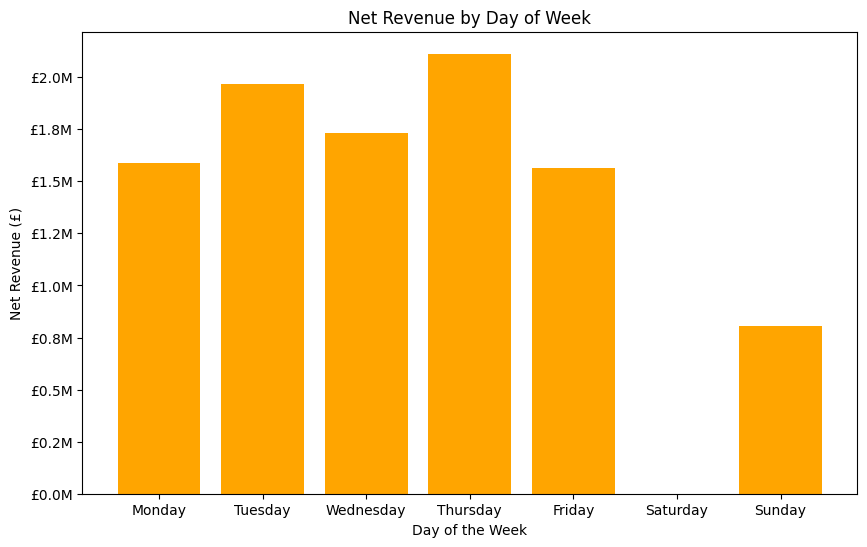

In [75]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x/1_000_000:.1f}M')
)

ax.bar(
    x=reindexed_by_day.index,
    height=reindexed_by_day.values,
    color='orange'
)

ax.set_xlabel('Day of the Week')
ax.set_ylabel('Net Revenue (£)')
ax.set_title('Net Revenue by Day of Week')

fig.savefig('net_revenue_by_day_of_week.png')


In [76]:
grouped_by_hour = sales_transactions_df.groupby('Hour')['TotalPrice'].sum()
sorted_by_hour = grouped_by_hour.sort_index()

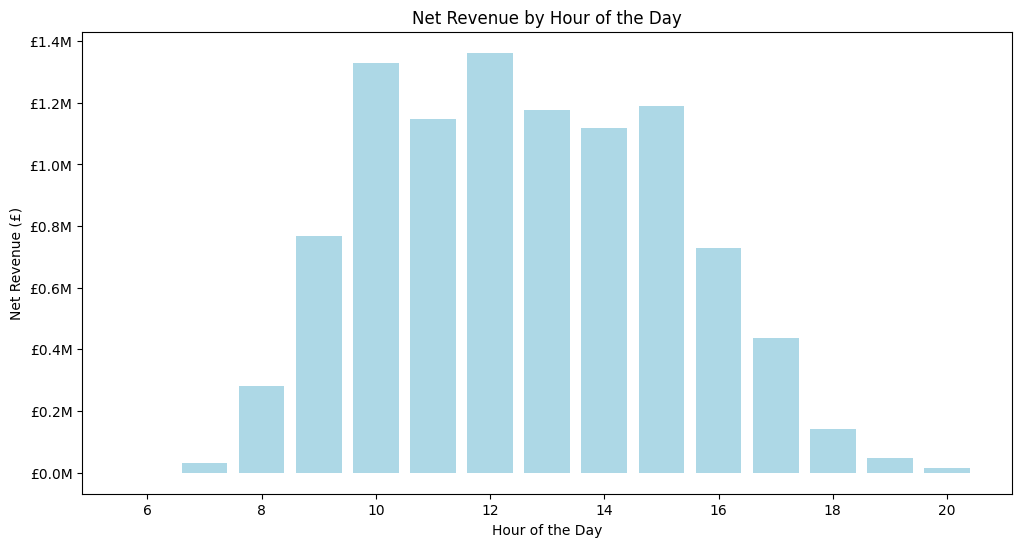

In [77]:
fig, ax = plt.subplots(figsize=(12,6))

ax.bar(
    x=sorted_by_hour.index,
    height=sorted_by_hour.values,
    color='lightblue'
)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x/1_000_000:.1f}M')
)

ax.set_xlabel('Hour of the Day')
ax.set_ylabel('Net Revenue (£)')
ax.set_title('Net Revenue by Hour of the Day')

fig.savefig('net_revenue_by_hour.png')

## 9. Final Business Insights, Recommendations, and Limitations

## Final Business Insights and Recommendations

### Executive Summary

This project analyzed 541,909 transaction-line records from a UK-based online retailer between December 2010 and December 2011. The objective was to identify historical sales trends, product performance, customer purchasing behaviour, geographic revenue concentration, and transaction patterns.

The business generated approximately **£10.67 million in gross merchandise sales**, offset by **£896,812.49 in cancellation-related value**, resulting in approximately **£9.77 million in net merchandise sales**. Separate bad-debt adjustments of £22,124.12 were excluded from merchandise-sales analysis.

### Key Findings

**1. Sales Performance**

Monthly net sales increased notably toward the end of 2011, with November recording the strongest monthly performance. December 2011 was incomplete and therefore cannot be compared directly with full months.

**2. Product Performance**

WORLD WAR 2 GLIDERS ASSTD DESIGNS recorded the highest net quantity sold, at 53,847 units. REGENCY CAKESTAND 3 TIER generated the highest net product revenue, approximately £164,762.

This demonstrates that the products selling the most units are not necessarily those generating the most revenue.

**3. Customer Purchasing Behaviour**

The ten highest-revenue customers contributed approximately 16.60% of identifiable net customer revenue.

Gross average order value was approximately £476.10. Among customers with AOV below £5,000, the Pearson correlation between purchase frequency and AOV was only 0.12, suggesting a very weak positive linear relationship.

**4. Geographic Revenue Distribution**

The United Kingdom generated approximately 84.03% of net merchandise revenue. The Netherlands, Ireland, Germany, and France were the largest international contributors.

This indicates substantial dependence on the domestic market.

**5. Repeat Purchasing**

Of 4,335 identifiable purchasing customers, 2,830 made more than one purchase, giving a repeat-purchase customer rate of 65.28%.

The average customer made 4.25 purchases, while the median was only two. Purchase frequency was strongly right-skewed, indicating that a relatively small group of customers purchased much more frequently than others.

**6. Transaction Timing**

Thursday generated the highest total weekday net revenue. Revenue recorded by invoice hour was concentrated around late morning and early afternoon, with noon showing the highest hourly total.

Invoice timestamps do not necessarily represent customer browsing times or the exact moment of order placement.

### Business Recommendations

**Inventory planning:** Monitor high-volume and high-revenue products separately when making stocking decisions. Product profitability and carrying costs should also be considered before allocating additional inventory.

**Customer engagement:** Investigate loyalty and retention initiatives for customers with recurring purchases, while separately examining one-time customers who may offer opportunities for repeat engagement.

**International growth:** Examine demand, distribution costs, and profitability in established international markets such as the Netherlands, Ireland, Germany, and France before considering expansion.

**Operational planning:** Use weekday and hourly transaction patterns as a starting point for reviewing order-processing and customer-support capacity, while validating patterns against transaction volumes and available staffing data.

**Data quality:** Maintain separate classifications for merchandise sales, cancellations, inventory adjustments, and accounting adjustments. This supports more consistent and interpretable financial reporting.

### Limitations

The dataset covers approximately one year of historical activity, with December 2011 incomplete. Missing customer identifiers restrict customer-level analysis. Recorded cancellations may not cover all returns or adjustments, and gross AOV does not reflect net retained revenue. Duplicate records and extreme transactions also require careful treatment.

These findings are descriptive and do not independently establish profitability, customer motivations, or the effectiveness of proposed business actions.

### Conclusion

The analysis shows a business with substantial UK revenue concentration, an active repeat-customer base, uneven purchase frequency, and notable differences between product sales volume and revenue contribution.

The findings provide a foundation for further investigation into inventory strategy, customer retention, international market development, and operational planning.

---
### Reproducibility and interpretation notes
- This notebook keeps the original transaction records intact and isolates merchandise transactions in `sales_transactions_df`.
- The six analyses use different appropriate populations: merchandise transactions for revenue; identifiable customers for customer metrics.
- Duplicate-row uncertainty, cancellation timing, incomplete December 2011, and unknown order-to-invoice processing delays limit interpretation.
- For an auditable final release, use **Restart & Run All** with `Online_Retail.xlsx`, inspect any failed cells, and save the notebook with refreshed outputs.